


# Dimensionality Reduction Analysis of Nav1.6 Proteomic Profiles
## for the manuscript:
#“CKB-Nav1.6 Coupling Confers Resilience Through Plasticity Control and Reward-Seeking Motivation”

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import matplotlib.patches as mpatches
from sklearn.preprocessing import StandardScaler

import scipy.stats as stats
from pandas.api.types import is_numeric_dtype
from scipy.stats import mannwhitneyu
import matplotlib.pyplot as plt


In [ ]:
#%load_ext google.colab.data_table
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

path = "/content/drive/My Drive/CKB/"


# 1) Male data

In [ ]:
df_filtered_M = pd.read_excel(path+"Filtered_Striatum_Male.xlsx")

df_filtered_M

,Unnamed: 0,Protein Name,Accession Number,SIM 1,SIM 2,SIM 3,SIM 4,SIM 5,SIM 6,SEM 1,SEM 2,SEM 3,SEM 4,SEM 5,SEM 6
0,1,Tubulin beta-2A chain OS=Rattus norvegicus OX=...,P85108,7.276000e+10,4.098358e+10,7.909074e+10,6.688208e+10,83654840000,1.384560e+11,4.785968e+10,3.710270e+10,3.390501e+10,8.087832e+10,74977240000,8.114534e+10
1,2,Tubulin beta-2B chain OS=Rattus norvegicus OX=...,Q3KRE8,7.278269e+10,4.080237e+10,7.895470e+10,6.506634e+10,83029490000,1.367800e+11,4.703865e+10,3.700482e+10,3.329031e+10,7.947218e+10,72683030000,7.860249e+10
2,2,Tubulin beta chain OS=Rattus norvegicus OX=101...,G3V7C6,6.983871e+10,3.959567e+10,7.809701e+10,6.548000e+10,79172590000,1.365100e+11,4.599273e+10,3.737222e+10,3.351049e+10,7.586178e+10,72702350000,7.468769e+10
3,3,Tubulin beta-5 chain OS=Rattus norvegicus OX=1...,P69897,7.337581e+10,4.044119e+10,7.829121e+10,6.659908e+10,80806070000,1.352410e+11,4.768386e+10,3.879116e+10,3.345307e+10,7.729360e+10,72711610000,7.731380e+10
4,4,Tubulin beta chain OS=Rattus norvegicus OX=101...,B4F7C2,6.362447e+10,3.590909e+10,7.231639e+10,5.973343e+10,71671370000,1.223440e+11,4.125219e+10,3.363080e+10,3.012524e+10,6.912906e+10,67644220000,6.853866e+10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1535,1758,Eukaryotic translation initiation factor 4E fa...,A0A096MK14,2.326985e+07,5.417578e+06,2.094819e+07,7.988493e+06,9655348,4.955287e+07,1.452750e+07,2.624352e+07,9.160493e+06,2.456838e+07,12723560,6.360568e+06
1536,1759,Bag2 protein OS=Rattus norvegicus OX=10116 GN=...,B0BN74,7.650392e+06,1.331982e+07,1.632094e+07,1.787935e+07,17467370,3.070478e+07,1.160985e+07,6.510243e+06,5.418084e+06,4.917683e+06,10971130,8.677079e+06
1537,1760,Choline-phosphate cytidylyltransferase A OS=Ra...,P19836,1.962682e+07,6.270336e+06,6.133189e+05,7.186719e+06,7182948,7.853261e+06,1.400977e+07,6.357817e+06,5.611263e+06,7.014641e+06,8375014,7.199142e+06
1538,1761,Translationally-controlled tumor protein OS=Ra...,P63029,3.201573e+06,7.210604e+06,9.174121e+06,6.921602e+06,8628352,5.644439e+06,3.964548e+06,9.651479e+06,3.793291e+06,3.400138e+06,4136363,3.754636e+06


In [ ]:

cols=['Unnamed: 0', 'Accession Number']
df_filtered1_M=df_filtered_M.drop(cols, axis=1)
expr_M = df_filtered1_M.set_index("Protein Name").T
expr_M["class"] = np.where(expr_M.index.str.startswith("SIM"), 0, 1)
expr_M

Protein Name,Tubulin beta-2A chain OS=Rattus norvegicus OX=10116 GN=Tubb2a PE=1 SV=1,Tubulin beta-2B chain OS=Rattus norvegicus OX=10116 GN=Tubb2b PE=1 SV=1,Tubulin beta chain OS=Rattus norvegicus OX=10116 GN=Tubb4b PE=1 SV=2,Tubulin beta-5 chain OS=Rattus norvegicus OX=10116 GN=Tubb5 PE=1 SV=1,Tubulin beta chain OS=Rattus norvegicus OX=10116 GN=Tubb4a PE=1 SV=1,Tubulin beta-3 chain OS=Rattus norvegicus OX=10116 GN=Tubb3 PE=1 SV=1,Tubulin alpha-1A chain OS=Rattus norvegicus OX=10116 GN=Tuba1a PE=1 SV=1,Tubulin alpha-1B chain OS=Rattus norvegicus OX=10116 GN=Tuba1b PE=1 SV=1,Serum albumin precursor (Allergen Bos d 6) (BSA),"Keratin, type II cytoskeletal 1 (Cytokeratin-1) (CK-1) (Keratin-1) (K1) (67 kDa cytokeratin) (Hair alpha protein)",...,Signal peptidase complex catalytic subunit SEC11 OS=Rattus norvegicus OX=10116 GN=Sec11a PE=1 SV=1,Leng4 protein OS=Rattus norvegicus OX=10116 GN=Mboat7 PE=2 SV=1,Cystatin-C OS=Rattus norvegicus OX=10116 GN=Cst3 PE=1 SV=2,Similar to Protein Njmu-R1 OS=Rattus norvegicus OX=10116 GN=RGD1310429 PE=1 SV=2,Eukaryotic translation initiation factor 4E family member 2 (Fragment) OS=Rattus norvegicus OX=10116 GN=Eif4e2 PE=1 SV=1,Bag2 protein OS=Rattus norvegicus OX=10116 GN=Bag2 PE=2 SV=1,Choline-phosphate cytidylyltransferase A OS=Rattus norvegicus OX=10116 GN=Pcyt1a PE=1 SV=2,Translationally-controlled tumor protein OS=Rattus norvegicus OX=10116 GN=Tpt1 PE=1 SV=1,COMM domain-containing protein 5 OS=Rattus norvegicus OX=10116 GN=Commd5 PE=2 SV=1,class
SIM 1,7.276000e+10,7.278269e+10,6.983871e+10,7.337581e+10,6.362447e+10,5.878546e+10,1.125680e+11,1.132100e+11,7.950849e+10,4.070259e+10,...,5476198.0,14233250.0,3359556.0,4491791.0,23269850.0,7650392.0,19626820.0,3201573.0,2304734.0,0
SIM 2,4.098358e+10,4.080237e+10,3.959567e+10,4.044119e+10,3.590909e+10,3.375488e+10,5.780885e+10,5.812772e+10,6.043110e+10,8.587608e+10,...,8572046.0,5495786.0,4380083.0,2823567.0,5417578.0,13319820.0,6270336.0,7210604.0,2502151.0,0
SIM 3,7.909074e+10,7.895470e+10,7.809701e+10,7.829121e+10,7.231639e+10,6.556849e+10,1.154810e+11,1.173100e+11,5.566920e+10,1.807511e+10,...,5877346.0,7598782.0,6361860.0,4731172.0,20948190.0,16320940.0,613318.9,9174121.0,2348863.0,0
SIM 4,6.688208e+10,6.506634e+10,6.548000e+10,6.659908e+10,5.973343e+10,5.879657e+10,1.007300e+11,1.015040e+11,5.812683e+10,2.252961e+10,...,9130680.0,7320127.0,4729100.0,6584928.0,7988493.0,17879350.0,7186719.0,6921602.0,10159080.0,0
SIM 5,8.365484e+10,8.302949e+10,7.917259e+10,8.080607e+10,7.167137e+10,6.318797e+10,1.243580e+11,1.255470e+11,5.747873e+10,5.435351e+10,...,10434960.0,9345397.0,5720712.0,4279119.0,9655348.0,17467370.0,7182948.0,8628352.0,10836280.0,0
SIM 6,1.384560e+11,1.367800e+11,1.365100e+11,1.352410e+11,1.223440e+11,1.019960e+11,1.923080e+11,1.926200e+11,3.529919e+10,2.680313e+10,...,20247000.0,12745610.0,4611500.0,5495008.0,49552870.0,30704780.0,7853261.0,5644439.0,13909160.0,0
SEM 1,4.785968e+10,4.703865e+10,4.599273e+10,4.768386e+10,4.125219e+10,3.611469e+10,5.969095e+10,5.977030e+10,6.054241e+10,4.242666e+10,...,11365190.0,5744971.0,4241031.0,3665962.0,14527500.0,11609850.0,14009770.0,3964548.0,11898110.0,1
SEM 2,3.710270e+10,3.700482e+10,3.737222e+10,3.879116e+10,3.363080e+10,3.092045e+10,5.829876e+10,5.941971e+10,4.257150e+10,1.534670e+11,...,12163740.0,8337654.0,6756947.0,3364291.0,26243520.0,6510243.0,6357817.0,9651479.0,7347900.0,1
SEM 3,3.390501e+10,3.329031e+10,3.351049e+10,3.345307e+10,3.012524e+10,2.766464e+10,4.754731e+10,4.789006e+10,4.634361e+10,7.375204e+10,...,6352883.0,6293974.0,4620968.0,2444907.0,9160493.0,5418084.0,5611263.0,3793291.0,2209850.0,1
SEM 4,8.087832e+10,7.947218e+10,7.586178e+10,7.729360e+10,6.912906e+10,6.619084e+10,1.186100e+11,1.201460e+11,5.072646e+10,4.250462e+10,...,6526195.0,11410330.0,6864703.0,9624463.0,24568380.0,4917683.0,7014641.0,3400138.0,5232922.0,1


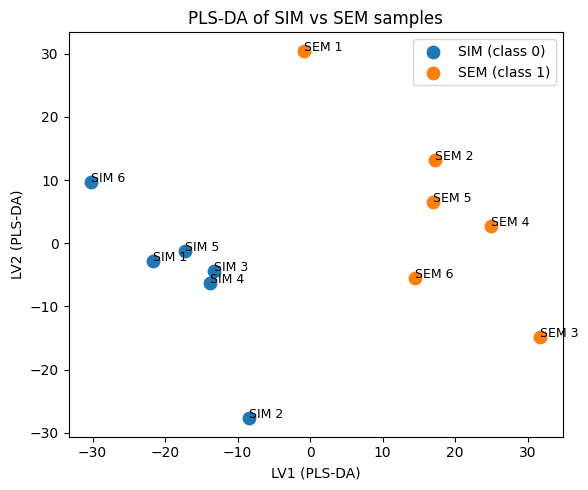

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cross_decomposition import PLSRegression
df=expr_M
# ----- 1) Split features and labels -----
# expr: rows = samples (SIM/SEM), columns = proteins + "class"
X_df = df.drop(columns=["class"])        # proteins
y = df["class"].values.reshape(-1, 1)    # 0 = SIM, 1 = SEM
samples = df.index

# ----- 2) Log-transform -----
X_log = np.log1p(X_df.values)

# ----- 3) Z-score per protein -----
scaler = StandardScaler()
X_log_scaled = scaler.fit_transform(X_log)

# ----- 4) PLS-DA (PLSRegression with class labels as Y) -----
# with 12 samples, 2 components is safe
pls = PLSRegression(n_components=2)
X_scores, Y_scores = pls.fit_transform(X_log_scaled, y)

# X_scores are the PLS-DA latent variables (LV1, LV2)
pls_df = pd.DataFrame({
    "LV1": X_scores[:, 0],
    "LV2": X_scores[:, 1],
    "class": y.ravel(),
    "sample": samples
})

# ----- 5) Plot LV1 vs LV2 with classes -----
plt.figure(figsize=(6, 5))
for cls, color, label in [
    (0, "tab:blue",  "SIM (class 0)"),
    (1, "tab:orange","SEM (class 1)")
]:
    sub = pls_df[pls_df["class"] == cls]
    plt.scatter(sub["LV1"], sub["LV2"], s=80, c=color, label=label)

# optional: text labels
for _, row in pls_df.iterrows():
    plt.text(row["LV1"], row["LV2"], row["sample"], fontsize=9)

plt.xlabel("LV1 (PLS-DA)")
plt.ylabel("LV2 (PLS-DA)")
plt.title("PLS-DA of SIM vs SEM samples")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
# Save LV1, LV2, class, and sample to a .txt file for Origin
#out_df = pls_df[["sample", "class", "LV1", "LV2"]]

#out_df.to_csv(path+"PLSDA_scores_M.txt", sep="\t", index=False)


In [ ]:
from sklearn.model_selection import LeaveOneOut

X = X_log_scaled
Y = y  # shape (n,1)

loo = LeaveOneOut()
y_true = []
y_pred = []

for train_idx, test_idx in loo.split(X):
    pls_cv = PLSRegression(n_components=2)
    pls_cv.fit(X[train_idx], Y[train_idx])
    # predict left-out sample
    y_hat = pls_cv.predict(X[test_idx])[0, 0]
    y_pred.append(y_hat)
    y_true.append(Y[test_idx][0, 0])

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# PRESS and TSS
PRESS = np.sum((y_true - y_pred) ** 2)
TSS   = np.sum((y_true - np.mean(y_true)) ** 2)

Q2 = 1 - PRESS / TSS
print("Q² (LOOCV) =", Q2)


Q² (LOOCV) = 0.7042915073635267


In [ ]:
from sklearn.metrics import r2_score

y_fit = pls.predict(X)[:, 0]
R2 = r2_score(Y[:, 0], y_fit)
print("R² (fit on all samples) =", R2)


R² (fit on all samples) = 0.9557546494145046


# 2) Female data

In [ ]:
df_filtered_F = pd.read_excel(path+"Filtered_Striatum_Female.xlsx")

df_filtered_F

,Unnamed: 0,Protein Name,Accession Number,SIF 1,SIF 2,SIF 3,SIF 4,SIF 5,SIF 6,SEF 1,SEF 2,SEF 3,SEF 4,SEF 5,SEF 6
0,0,Tubulin beta-2A chain OS=Rattus norvegicus OX=...,P85108,5.328505e+10,41162160000,62357060000,1.740905e+10,37047590000,21715650000,1.206060e+11,3.487191e+10,2.757676e+10,1.822281e+10,1.798393e+10,4.004336e+10
1,1,Tubulin beta-2B chain OS=Rattus norvegicus OX=...,Q3KRE8,5.192402e+10,40099320000,61827080000,1.722451e+10,36554160000,21378730000,1.171680e+11,3.454767e+10,2.687302e+10,1.747612e+10,1.766727e+10,3.885364e+10
2,2,Tubulin beta chain OS=Rattus norvegicus OX=101...,G3V7C6,5.281350e+10,42210790000,62098250000,1.697794e+10,37460790000,22192810000,1.138590e+11,3.332257e+10,2.568866e+10,1.707317e+10,1.848307e+10,3.933162e+10
3,3,Tubulin beta-5 chain OS=Rattus norvegicus OX=1...,P69897,5.295146e+10,41637340000,61650690000,1.683564e+10,37011000000,20799150000,1.142900e+11,3.389452e+10,2.550323e+10,1.736213e+10,1.753921e+10,3.873795e+10
4,4,Tubulin beta chain OS=Rattus norvegicus OX=101...,B4F7C2,4.826495e+10,38803590000,54935720000,1.511101e+10,32823930000,19511720000,1.051020e+11,3.047649e+10,2.213859e+10,1.495648e+10,1.550149e+10,3.635571e+10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1043,1209,Ethylmalonyl-CoA decarboxylase OS=Rattus norve...,Q6AYG5,1.200974e+07,9120460,18194920,3.349571e+06,8394070,7126123,1.403961e+07,8.194928e+06,6.235624e+06,5.759124e+06,6.674849e+06,5.866966e+06
1044,1210,Rho-related GTP-binding protein RhoB OS=Rattus...,P62747,6.464337e+06,4112344,22699670,6.842880e+06,13647610,18715360,8.903644e+06,1.074610e+07,9.132564e+06,5.309432e+06,2.008330e+05,1.160856e+07
1045,1212,Myristoylated alanine-rich C-kinase substrate ...,P30009,1.860407e+07,32854430,21906420,2.251944e+07,17689920,24858390,1.714766e+07,3.751463e+07,2.668210e+07,1.692070e+07,1.991357e+07,3.649957e+07
1046,1215,PC4 and SFRS1-interacting protein OS=Rattus no...,Q812D1,4.017962e+07,24964380,56759970,7.223235e+06,35319470,29598950,3.399119e+07,1.870069e+07,1.429309e+07,1.116820e+07,1.230738e+07,3.052361e+07


In [ ]:
cols=['Unnamed: 0', 'Accession Number']
df_filtered1_F=df_filtered_F.drop(cols, axis=1)
expr_F = df_filtered1_F.set_index("Protein Name").T
expr_F["class"] = np.where(expr_F.index.str.startswith("SIF"), 0, 1)
expr_F

Protein Name,Tubulin beta-2A chain OS=Rattus norvegicus OX=10116 GN=Tubb2a PE=1 SV=1,Tubulin beta-2B chain OS=Rattus norvegicus OX=10116 GN=Tubb2b PE=1 SV=1,Tubulin beta chain OS=Rattus norvegicus OX=10116 GN=Tubb4b PE=1 SV=2,Tubulin beta-5 chain OS=Rattus norvegicus OX=10116 GN=Tubb5 PE=1 SV=1,Tubulin beta chain OS=Rattus norvegicus OX=10116 GN=Tubb4a PE=1 SV=1,Tubulin beta-3 chain OS=Rattus norvegicus OX=10116 GN=Tubb3 PE=1 SV=1,Tubulin alpha-1A chain OS=Rattus norvegicus OX=10116 GN=Tuba1a PE=1 SV=1,Tubulin alpha-1B chain OS=Rattus norvegicus OX=10116 GN=Tuba1b PE=1 SV=1,Tubulin alpha-4A chain OS=Rattus norvegicus OX=10116 GN=Tuba4a PE=1 SV=1,Microtubule-associated protein OS=Rattus norvegicus OX=10116 GN=Map2 PE=1 SV=3,...,Protein-ribulosamine 3-kinase OS=Rattus norvegicus OX=10116 GN=Fn3krp PE=1 SV=1,RUN and FYVE domain-containing 1 OS=Rattus norvegicus OX=10116 GN=Rufy1 PE=1 SV=1,"TAF15 RNA polymerase II, TATA box binding protein (TBP)-associated factor (Predicted), isoform CRA_a OS=Rattus norvegicus OX=10116 GN=Taf15 PE=3 SV=1","1,4-alpha-glucan branching enzyme OS=Rattus norvegicus OX=10116 GN=Gbe1 PE=1 SV=1",Ethylmalonyl-CoA decarboxylase OS=Rattus norvegicus OX=10116 GN=Echdc1 PE=1 SV=1,Rho-related GTP-binding protein RhoB OS=Rattus norvegicus OX=10116 GN=Rhob PE=1 SV=1,Myristoylated alanine-rich C-kinase substrate OS=Rattus norvegicus OX=10116 GN=Marcks PE=1 SV=2,PC4 and SFRS1-interacting protein OS=Rattus norvegicus OX=10116 GN=Psip1 PE=1 SV=1,G-protein coupled receptor 37-like 1 OS=Rattus norvegicus OX=10116 GN=Gpr37l1 PE=1 SV=1,class
SIF 1,5.328505e+10,5.192402e+10,5.281350e+10,5.295146e+10,4.826495e+10,4.622358e+10,7.998358e+10,7.981129e+10,5.567422e+10,1.210795e+10,...,14651420.0,52079660.0,16241800.0,23240130.0,12009740.0,6464337.0,18604070.0,40179620.0,27758990.0,0
SIF 2,4.116216e+10,4.009932e+10,4.221079e+10,4.163734e+10,3.880359e+10,3.851648e+10,7.683078e+10,7.680716e+10,5.548139e+10,7.093002e+09,...,20307470.0,35986570.0,23068080.0,12873990.0,9120460.0,4112344.0,32854430.0,24964380.0,28023550.0,0
SIF 3,6.235706e+10,6.182708e+10,6.209825e+10,6.165069e+10,5.493572e+10,4.685617e+10,9.374676e+10,9.334639e+10,7.547363e+10,1.159383e+10,...,24761900.0,47998190.0,44568240.0,19181880.0,18194920.0,22699670.0,21906420.0,56759970.0,28518510.0,0
SIF 4,1.740905e+10,1.722451e+10,1.697794e+10,1.683564e+10,1.511101e+10,1.518506e+10,2.806838e+10,2.809070e+10,2.157037e+10,3.073139e+09,...,9063410.0,21145720.0,12250760.0,4803082.0,3349571.0,6842880.0,22519440.0,7223235.0,15913320.0,0
SIF 5,3.704759e+10,3.655416e+10,3.746079e+10,3.701100e+10,3.282393e+10,3.027578e+10,5.447276e+10,5.461493e+10,4.372414e+10,8.401069e+09,...,12364890.0,39429080.0,21017140.0,16440220.0,8394070.0,13647610.0,17689920.0,35319470.0,20355440.0,0
SIF 6,2.171565e+10,2.137873e+10,2.219281e+10,2.079915e+10,1.951172e+10,1.701232e+10,3.686491e+10,3.699434e+10,2.822637e+10,3.622080e+09,...,15893220.0,25661260.0,1300279.0,11802290.0,7126123.0,18715360.0,24858390.0,29598950.0,22502560.0,0
SEF 1,1.206060e+11,1.171680e+11,1.138590e+11,1.142900e+11,1.051020e+11,9.888090e+10,1.956950e+11,1.955980e+11,1.583220e+11,1.508499e+10,...,12088560.0,44070250.0,24659080.0,4955489.0,14039610.0,8903644.0,17147660.0,33991190.0,20750040.0,1
SEF 2,3.487191e+10,3.454767e+10,3.332257e+10,3.389452e+10,3.047649e+10,2.952229e+10,5.774275e+10,5.712816e+10,4.548602e+10,6.420355e+09,...,14093930.0,17790960.0,48099210.0,4683807.0,8194928.0,10746100.0,37514630.0,18700690.0,12906870.0,1
SEF 3,2.757676e+10,2.687302e+10,2.568866e+10,2.550323e+10,2.213859e+10,2.030932e+10,3.943263e+10,3.941531e+10,2.969178e+10,3.160716e+09,...,10482040.0,17699250.0,18077830.0,4893876.0,6235624.0,9132564.0,26682100.0,14293090.0,15691150.0,1
SEF 4,1.822281e+10,1.747612e+10,1.707317e+10,1.736213e+10,1.495648e+10,1.512350e+10,3.233814e+10,3.242155e+10,2.312305e+10,3.164744e+09,...,8800264.0,19192190.0,11809360.0,4562457.0,5759124.0,5309432.0,16920700.0,11168200.0,9865003.0,1


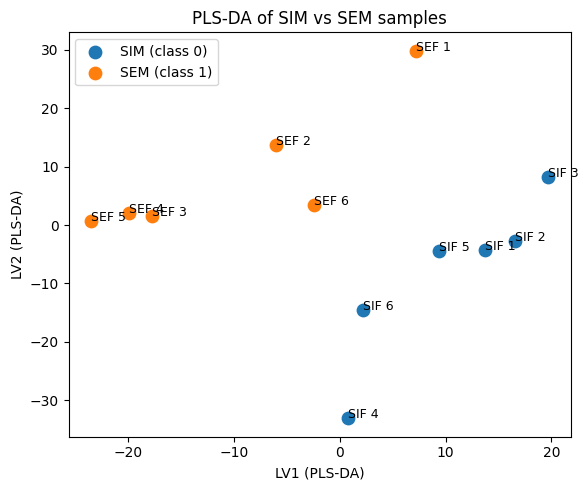

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cross_decomposition import PLSRegression
df=expr_F
# ----- 1) Split features and labels -----
# expr: rows = samples (SIM/SEM), columns = proteins + "class"
X_df = df.drop(columns=["class"])        # proteins
y = df["class"].values.reshape(-1, 1)    # 0 = SIM, 1 = SEM
samples = df.index

# ----- 2) Log-transform -----
X_log = np.log1p(X_df.values)

# ----- 3) Z-score per protein -----
scaler = StandardScaler()
X_log_scaled = scaler.fit_transform(X_log)

# ----- 4) PLS-DA (PLSRegression with class labels as Y) -----
# with 12 samples, 2 components is safe
pls = PLSRegression(n_components=2)
X_scores, Y_scores = pls.fit_transform(X_log_scaled, y)

# X_scores are the PLS-DA latent variables (LV1, LV2)
pls_df = pd.DataFrame({
    "LV1": X_scores[:, 0],
    "LV2": X_scores[:, 1],
    "class": y.ravel(),
    "sample": samples
})

# ----- 5) Plot LV1 vs LV2 with classes -----
plt.figure(figsize=(6, 5))
for cls, color, label in [
    (0, "tab:blue",  "SIM (class 0)"),
    (1, "tab:orange","SEM (class 1)")
]:
    sub = pls_df[pls_df["class"] == cls]
    plt.scatter(sub["LV1"], sub["LV2"], s=80, c=color, label=label)

# optional: text labels
for _, row in pls_df.iterrows():
    plt.text(row["LV1"], row["LV2"], row["sample"], fontsize=9)

plt.xlabel("LV1 (PLS-DA)")
plt.ylabel("LV2 (PLS-DA)")
plt.title("PLS-DA of SIM vs SEM samples")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
# Save LV1, LV2, class, and sample to a .txt file for Origin
#out_df = pls_df[["sample", "class", "LV1", "LV2"]]

#out_df.to_csv(path+"PLSDA_scores_F.txt", sep="\t", index=False)


In [ ]:
from sklearn.model_selection import LeaveOneOut

X = X_log_scaled
Y = y  # shape (n,1)

loo = LeaveOneOut()
y_true = []
y_pred = []

for train_idx, test_idx in loo.split(X):
    pls_cv = PLSRegression(n_components=2)
    pls_cv.fit(X[train_idx], Y[train_idx])
    # predict left-out sample
    y_hat = pls_cv.predict(X[test_idx])[0, 0]
    y_pred.append(y_hat)
    y_true.append(Y[test_idx][0, 0])

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# PRESS and TSS
PRESS = np.sum((y_true - y_pred) ** 2)
TSS   = np.sum((y_true - np.mean(y_true)) ** 2)

Q2 = 1 - PRESS / TSS
print("Q² (LOOCV) =", Q2)


Q² (LOOCV) = 0.4445566212824015


In [ ]:
from sklearn.metrics import r2_score

y_fit = pls.predict(X)[:, 0]
R2 = r2_score(Y[:, 0], y_fit)
print("R² (fit on all samples) =", R2)


R² (fit on all samples) = 0.9080408823288899
